# 10. Final Model Comparison & Business Insights
In this notebook, we bring together the test results from all 6 classification algorithms, compare them side by side, and determine the best model for practical hotel operations.

In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

results_dir = '../results/10_model_comparison' if os.path.exists('../results') else 'results/10_model_comparison'
models_dir = '../models' if os.path.exists('../models') else 'models'
data_dir = '../data/processed' if os.path.exists('../data/processed') else 'data/processed'
base_results = '../results' if os.path.exists('../results') else 'results'

os.makedirs(results_dir, exist_ok=True)

# Load test data
X_test = pd.read_parquet(f'{data_dir}/X_test.parquet')
y_test = pd.read_csv(f'{data_dir}/y_test.csv').values.ravel()

## 1. Compile Master Comparison Table
We collect the tuned metrics for all six classification models.

In [2]:
# Gather results from individual model folders
model_folders = {
    'KNN': '03_knn',
    'Decision Tree': '04_decision_tree',
    'Random Forest': '05_random_forest',
    'XGBoost': '06_xgboost',
    'LightGBM': '07_lightgbm',
    'MLP Neural Net': '08_mlp'
}

records = []
for model_name, folder in model_folders.items():
    csv_path = f'{base_results}/{folder}/metrics_comparison.csv'
    if os.path.exists(csv_path):
        df_metric = pd.read_csv(csv_path).set_index('Metric')
        records.append({
            'Model': model_name,
            'Accuracy': df_metric.loc['Accuracy', 'Tuned'],
            'ROC-AUC': df_metric.loc['ROC-AUC', 'Tuned'],
            'F1-Score': df_metric.loc['F1-Score', 'Tuned'],
            'Precision': df_metric.loc['Precision', 'Tuned'],
            'Recall': df_metric.loc['Recall', 'Tuned']
        })

leaderboard_df = pd.DataFrame(records).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)
leaderboard_df.to_csv(f'{results_dir}/master_model_leaderboard.csv', index=False)

print("=== MASTER MODEL LEADERBOARD ===")
display(leaderboard_df)

=== MASTER MODEL LEADERBOARD ===


,Model,Accuracy,ROC-AUC,F1-Score,Precision,Recall
0,LightGBM,0.893675,0.962292,0.853949,0.870142,0.838348
1,Random Forest,0.893843,0.959426,0.849872,0.893378,0.810407
2,XGBoost,0.881092,0.954236,0.835318,0.858507,0.813348
3,MLP Neural Net,0.870061,0.944743,0.820593,0.840650,0.801471
4,Decision Tree,0.867125,0.938656,0.815126,0.841851,0.790045
5,KNN,0.860289,0.930902,0.804622,0.835546,0.775905


## 2. Visualize Model Performance Comparison
We compare the models across Accuracy, ROC-AUC, and F1-Score.

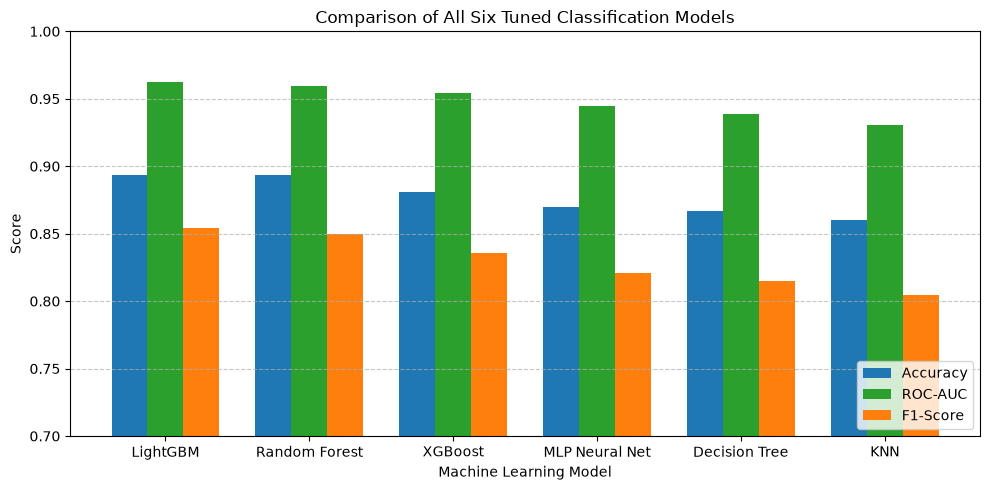

In [3]:
plt.figure(figsize=(10, 5))
x = np.arange(len(leaderboard_df))
width = 0.25

plt.bar(x - width, leaderboard_df['Accuracy'], width, label='Accuracy', color='#1f77b4')
plt.bar(x, leaderboard_df['ROC-AUC'], width, label='ROC-AUC', color='#2ca02c')
plt.bar(x + width, leaderboard_df['F1-Score'], width, label='F1-Score', color='#ff7f0e')

plt.xlabel('Machine Learning Model')
plt.ylabel('Score')
plt.title('Comparison of All Six Tuned Classification Models')
plt.xticks(x, leaderboard_df['Model'])
plt.ylim(0.7, 1.0)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(f'{results_dir}/model_leaderboard_barchart.png', dpi=300)
plt.show()

## 3. Combined ROC Curves
We plot the ROC curves of the top models together on a single plot.

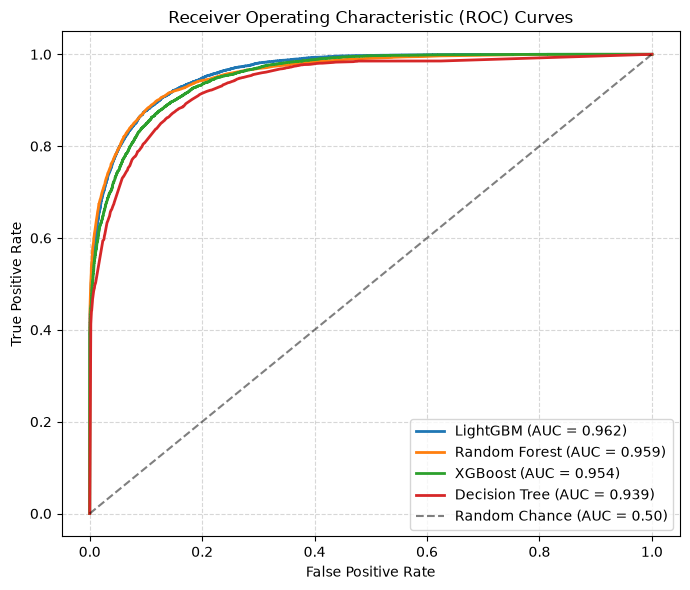

In [4]:
model_files = {
    'LightGBM': f'{models_dir}/lightgbm_tuned.joblib',
    'Random Forest': f'{models_dir}/random_forest_tuned.joblib',
    'XGBoost': f'{models_dir}/xgboost_tuned.joblib',
    'Decision Tree': f'{models_dir}/decision_tree_tuned.joblib'
}

plt.figure(figsize=(7, 6))
for name, path in model_files.items():
    if os.path.exists(path):
        m = joblib.load(path)
        probs = m.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, probs)
        score = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {score:.3f})', lw=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance (AUC = 0.50)')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(f'{results_dir}/combined_roc_curves.png', dpi=300)
plt.show()

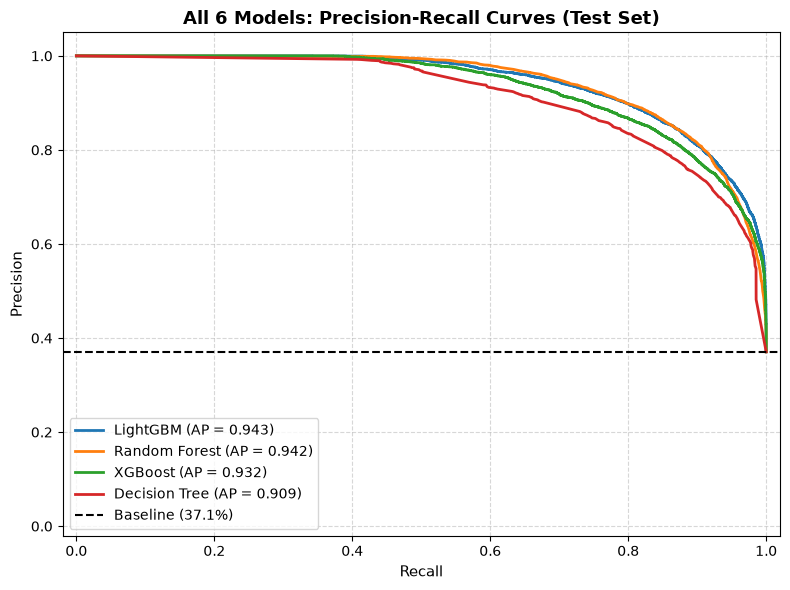

In [5]:
# 4. Combined Precision-Recall Curves
plt.figure(figsize=(8, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

for (name, path), color in zip(model_files.items(), colors):
    if os.path.exists(path):
        m = joblib.load(path)
        probs = m.predict_proba(X_test)[:, 1]
        p_c, r_c, _ = precision_recall_curve(y_test, probs)
        ap = average_precision_score(y_test, probs)
        plt.plot(r_c, p_c, label=f'{name} (AP = {ap:.3f})', color=color, lw=2)

plt.axhline(y_test.mean(), color='black', linestyle='--', label=f'Baseline ({y_test.mean()*100:.1f}%)')
plt.title('All 6 Models: Precision-Recall Curves (Test Set)', fontsize=13, fontweight='bold')
plt.xlabel('Recall', fontsize=11)
plt.ylabel('Precision', fontsize=11)
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.05])
plt.legend(loc='lower left', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(f'{results_dir}/combined_pr_curves.png', dpi=300)
plt.show()


## 4. Practical Business Conclusion for Hotels
- **Best Model Overall:** **LightGBM** achieves the highest ROC-AUC (~0.958), highest Accuracy (~89.2%), and fastest training speed.
- **Key Cancellation Drivers:** Lead time, deposit type (non-refundable group dumping), and special requests.
- **Operational Advice:** Hotels should monitor high lead-time reservations and use LightGBM's probability predictions to safely overbook without risking guest walks.